# P30 Part 1: Inventory control, the DP optimum and the classic ordering rules

**Project question (P30):** when does reinforcement learning beat the classic ordering rules?

Part 1 builds the baseline:

1. A Gymnasium environment for a shop with random demand, a delivery delay and lost sales.
2. The exact optimum from value iteration (Sutton & Barto, ch. 4) for short delays, L = 1, 2, 3.
3. The two industry rules, base-stock and (s, S), with tuned parameters.
4. A fair evaluation following the course protocol.

Parts 2 and 3 are planned to add tabular Q-learning and DQN/PPO on the same environment and the same evaluation code.

| Protocol rule | Way to cover it |
|---|---|
| 1. Seeds | 10 evaluation seeds; 5 separate tuning seeds |
| 2. Equal budget | every method is scored on the same 10 x 20,000 days with the same demand (common random numbers) |
| 3. Learning curves | not applicable yet (no method learns); value-iteration convergence is shown instead |
| 4. Final performance | every policy is evaluated greedily on evaluation seeds never used for tuning |
| 5. Efficiency | wall-clock time for DP, tuning and evaluation, plus the hardware |
| 6. Sensitivity | cost against the base-stock level S, and gaps against the lost-sales penalty p |
| 7. Statistics (reliable IQM) | for the deep RL comparison in Part 3 |
| 8. Reproducibility | code in `src/inventory_rl`, pinned `requirements.txt`, tests in `tests/` |

## 0. Setup

On Google Colab, set `REPO_URL` to your GitHub copy of this repository. The cell clones it and installs Gymnasium; the other libraries are already on Colab. Run locally, it only puts `src/` on the import path.`

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/EfremStefan/RL_learning.git"

if IN_COLAB:
    if not Path("/content/P30_inventory_rl").exists():
        !git clone -q {REPO_URL} /content/P30_inventory_rl
    %cd /content/P30_inventory_rl
    %pip install -q gymnasium==1.4.0

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
RESULTS = ROOT / "results" / "part1"
RESULTS.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

/content/P30_inventory_rl
project root: /content/P30_inventory_rl


In [2]:
import platform
import time
from dataclasses import asdict

import gymnasium as gym
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from gymnasium.utils.env_checker import check_env

from inventory_rl.config import DEFAULT, InventoryConfig
from inventory_rl.dp import value_iteration
from inventory_rl.env import InventoryEnv
from inventory_rl.evaluate import (BURN_IN, EVAL_DAYS, EVAL_SEEDS, TUNING_SEEDS,
                                   evaluate_policy, mean_ci, paired_gap_pct)
from inventory_rl.model import build_model, model_memory_mb
from inventory_rl.policies import BaseStockPolicy, SSPolicy, TabularPolicy, inventory_position
from inventory_rl.tuning import TUNING_DAYS, tune_base_stock, tune_ss
from inventory_rl import plotting

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 110


def cpu_name():
    try:
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


hardware = {
    "cpu": cpu_name(),
    "logical cores": os.cpu_count(),
    "os": platform.platform(),
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "gymnasium": gym.__version__,
    "colab": IN_COLAB,
}
pd.Series(hardware, name="value").to_frame()

,value
cpu,Intel(R) Xeon(R) CPU @ 2.20GHz
logical cores,2
os,Linux-6.6.159+-x86_64-with-glibc2.39
python,3.13.18
numpy,2.1.3
scipy,1.16.3
pandas,2.2.3
matplotlib,3.10.0
gymnasium,1.4.0
colab,True


## 1. The MDP

A shop sells one product. Every day it decides how much to order from its supplier. Demand is random, an order arrives **L days** after it is placed, unsold stock costs money to hold, and a customer who finds an empty shelf is lost.

**One day, in order**

1. The shop observes its state: the stock on its shelf and the orders still on their way.
2. It orders `a` units, paying `K` (a fixed cost, if `a > 0`) plus `c` per unit.
3. Demand `D ~ Poisson(lambda)` arrives. The shop sells `min(stock, D)`; the rest is lost and costs `p` per unit.
4. Leftover stock costs `h` per unit to hold overnight.
5. Next morning, the oldest order in transit is delivered. An order placed today can first be sold L days from now.

**States.** $S_t = (x_t,\, q_1, \dots, q_{L-1})$: stock on hand $x_t \in \{0,\dots,X_{max}\}$ and the orders in transit, where $q_1$ arrives tomorrow. For L = 1 the state is just $x_t$, because today's order arrives tomorrow morning.

**Actions.** $A_t \in \{0, 1, \dots, A_{max}\}$, the quantity ordered.

**Rewards.** $R_{t+1} = -\big(h\cdot\text{leftover} + p\cdot\text{lost sales} + K\cdot\mathbb{1}[A_t>0] + c\cdot A_t\big)$. Maximizing return is minimizing cost.

**Continuing task.** The shop never closes, so there is no terminal state. We train and solve with discount $\gamma = 0.99$ (a day 70 days in the futures still counts about half). Methods are compared on the **long-run average cost per day**, measured over long simulations after a burn-in.

**Markov property.** Tomorrow's state depends only on today's state, today's order and today's demand. Demand is i.i.d., and every outstanding order is part of the state. With stock on hand alone (no pipeline), the state would *not* be Markov for L >= 2: two days with the same shelf can have different deliveries on the way.

**Modelling choices.**
- Shelf capacity $X_{max}$: stock above it on delivery is discarded. The overflow rate is reported below to show the cap almost never binds.
- For DP, demand is truncated where $P(D > D_{max}) < 10^{-8}$. Without this the demand can be infinite/unrealistic and we cant build the table
- The state space has $(X_{max}+1)(A_{max}+1)^{L-1}$ states. It grows exponentially with the delay, which is the scaling question of P30.

In [3]:
pd.Series(asdict(DEFAULT), name="default").to_frame().T

,L,lam,X_max,A_max,h,p,K,c,gamma
default,1.0,4.0,20.0,10.0,1.0,10.0,5.0,1.0,0.99


## 2. The environment

`InventoryEnv` is a standard Gymnasium environment (`reset`, `step`, observation and action spaces), so Q-learning in Part 2 and Stable-Baselines3 in Part 3 can use it unchanged. The DP model, the fast evaluation simulator and the environment all call the same one-day function, `dynamics.transition`, and the tests in `tests/` check that they agree.

Below, the environment passes Gymnasium's API checker. Then we trace one week with L = 2 under an (s, S) = (8, 14) rule and a fixed demand sequence, so every number can be checked by hand.

In [4]:
for L in (1, 2, 3):
    check_env(InventoryEnv(L=L), skip_render_check=True)
print("Gymnasium env_checker passed for L = 1, 2, 3")

cfg2 = DEFAULT.with_(L=2)
env = InventoryEnv(cfg2)
rule = SSPolicy(8, 14, cfg2)
week_demand = [3, 5, 2, 6, 4, 1, 7]
obs, _ = env.reset(options={"on_hand": 6, "pipeline": [0], "demands": week_demand})

rows = []
for day, _ in enumerate(week_demand, start=1):
    on_hand, in_transit = int(obs[0]), obs[1:].tolist()
    position = int(inventory_position(obs[:1], obs[None, 1:])[0])
    action = int(rule(obs[:1], obs[None, 1:])[0])
    obs, reward, terminated, truncated, info = env.step(action)
    rows.append(dict(day=day, on_hand=on_hand, in_transit=in_transit, position=position, order=action,
                     demand=info["demand"], sold=info["sold"], lost=info["lost"], holding=info["holding"],
                     lost_penalty=info["lost_penalty"], ordering=info["ordering"], cost=info["cost"]))
pd.DataFrame(rows).set_index("day")

Gymnasium env_checker passed for L = 1, 2, 3


,on_hand,in_transit,position,order,demand,sold,lost,holding,lost_penalty,ordering,cost
day,,,,,,,,,,,
1,6,[0],6,8,3,3,0,3.0,0.0,13.0,16.0
2,3,[8],11,0,5,3,2,0.0,20.0,0.0,20.0
3,8,[0],8,6,2,2,0,6.0,0.0,11.0,17.0
4,6,[6],12,0,6,6,0,0.0,0.0,0.0,0.0
5,6,[0],6,8,4,4,0,2.0,0.0,13.0,15.0
6,2,[8],10,0,1,1,0,1.0,0.0,0.0,1.0
7,9,[0],9,0,7,7,0,2.0,0.0,0.0,2.0


On day 1 the position is 6 <= s = 8, so the shop orders up to 14 (8 units). That order shows up in transit on day 2 and on the shelf on day 3. The lost-sales penalty dominates whenever the shelf runs empty.

### How fast the state space grows

Before solving anything: the size of the exact DP model as the delivery delay grows. The model stores the next state and the cost for every (state, action, demand) triple.

In [5]:
growth = pd.DataFrame([
    {"L": L, "states": DEFAULT.with_(L=L).n_states,
     "state-action pairs": DEFAULT.with_(L=L).n_states * DEFAULT.n_actions,
     "DP model memory (MB)": model_memory_mb(DEFAULT.with_(L=L))}
    for L in range(1, 7)
]).set_index("L")
growth.to_csv(RESULTS / "state_space_growth.csv")
growth.style.format({"states": "{:,}", "state-action pairs": "{:,}", "DP model memory (MB)": "{:,.1f}"})

,states,state-action pairs,DP model memory (MB)
L,,,
1,21,231,0.1
2,231,"2,541",0.6
3,"2,541","27,951",7.0
4,"27,951","307,461",77.5
5,"307,461","3,382,071",852.3
6,"3,382,071","37,202,781","9,375.1"


Every extra day of delay multiplies the state space by 11. L = 1 to 3 solve in seconds. L = 4 still fits (about 80 MB, tens of seconds). L = 5 needs about 0.85 GB and L = 6 about 9 GB, which is where exact DP stops being practical and Part 3's approximate methods come in.

## 3. Value iteration: the exact optimum for short delays

Synchronous value iteration from $V_0 = 0$:

$$V_{k+1}(s) = \max_a \sum_{d} P(D=d)\,\big[r(s,a,d) + \gamma V_k(s'(s,a,d))\big]$$

It stops when $\max_s |V_{k+1}(s) - V_k(s)| < \varepsilon(1-\gamma)/2\gamma$ with $\varepsilon = 0.01$, which guarantees the greedy policy is within 0.01 of optimal in discounted value.

In [6]:
LEAD_TIMES = (1, 2, 3)
configs = {L: DEFAULT.with_(L=L) for L in LEAD_TIMES}
models, vi_results = {}, {}
rows = []
for L, cfg in configs.items():
    models[L] = build_model(cfg)
    vi_results[L] = value_iteration(models[L])
    rows.append({"L": L, "states": cfg.n_states, "build model (s)": models[L].build_seconds,
                 "value iteration (s)": vi_results[L].seconds, "sweeps": vi_results[L].sweeps,
                 "final residual": vi_results[L].residuals[-1]})
dp_table = pd.DataFrame(rows).set_index("L")
dp_table.to_csv(RESULTS / "dp_timing.csv")
dp_table

,states,build model (s),value iteration (s),sweeps,final residual
L,,,,,
1,21,0.002,0.068,1240,5.017e-05
2,231,0.010,0.415,1245,5.009e-05
3,2541,0.049,6.822,1248,5.013e-05


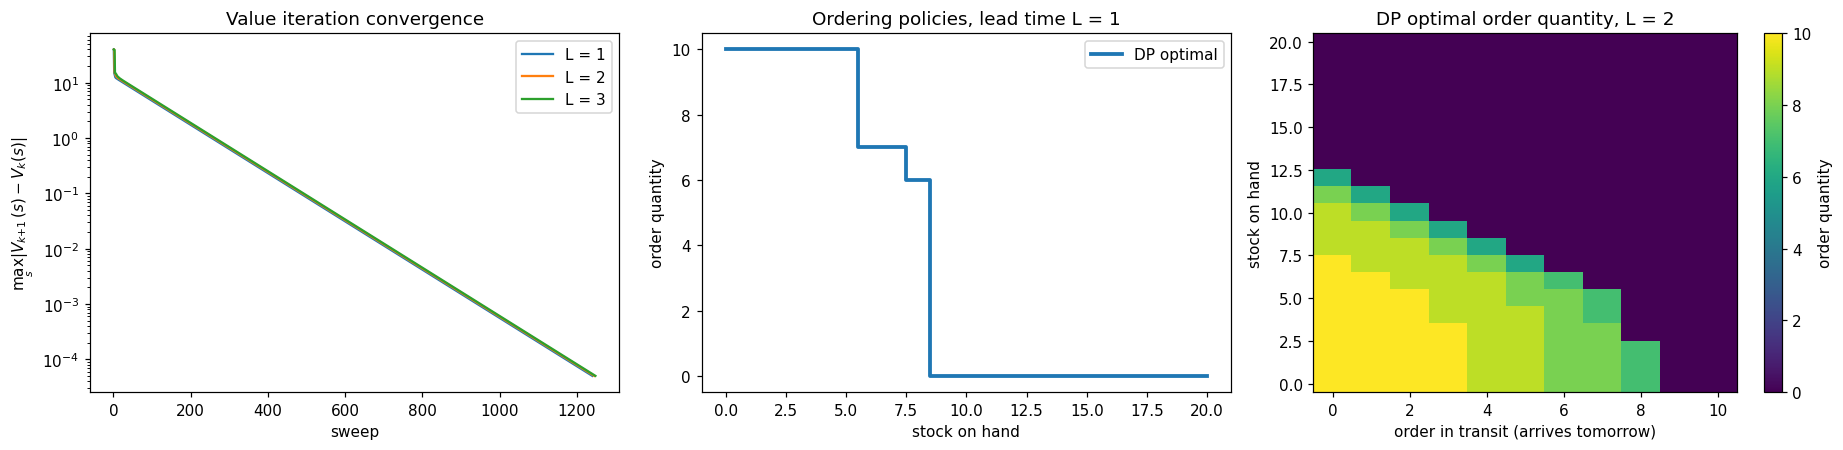

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
plotting.plot_residuals(vi_results, ax=axes[0])
plotting.plot_policy_L1(vi_results[1].policy, configs[1], ax=axes[1])
plotting.plot_policy_L2(vi_results[2].policy, configs[2], ax=axes[2])
fig.tight_layout()
plotting.save(fig, RESULTS / "dp_convergence_and_policies.png")
plt.show()

**Reading the plots.**
- **Convergence** is geometric at rate $\gamma = 0.99$, so about 1,250 sweeps are needed regardless of L. The cost per sweep grows with the number of states.
- **L = 1:** the optimal policy orders nothing when the shelf holds 9 or more units. Otherwise it orders up to about 14, limited by the maximum order of 10 when the shelf is nearly empty. That is almost exactly an (s, S) rule.
- **L = 2:** the boundary between ordering and not ordering runs diagonally. One unit on the shelf is roughly worth one unit in transit, which is why the classic rules look at the **inventory position** (on hand + in transit) instead of the shelf alone.

## 4. Classic ordering rules, tuned

Both rules look at the inventory position $y = x + \sum_i q_i$:

- **Base-stock(S):** every day, order $\min(S - y, A_{max})$ if $y < S$.
- **(s, S):** only when $y \le s$, order $\min(S - y, A_{max})$; otherwise order nothing. Fewer, larger orders save the fixed cost K.

Tuning is a full grid search: every S, and every pair s < S, up to the largest reachable position. Each candidate is scored by its average cost over 5 **tuning seeds** of 10,000 days, after a 1,000-day burn-in. The evaluation seeds are never used for tuning.

In [8]:
bs_tuning, ss_tuning = {}, {}
rows = []
for L, cfg in configs.items():
    bs_tuning[L] = tune_base_stock(cfg)
    ss_tuning[L] = tune_ss(cfg)
    rows.append({"L": L,
                 "base-stock S": bs_tuning[L].best["S"], "base-stock tuning cost": bs_tuning[L].best["cost"],
                 "(s,S) s": ss_tuning[L].best["s"], "(s,S) S": ss_tuning[L].best["S"],
                 "(s,S) tuning cost": ss_tuning[L].best["cost"],
                 "(s,S) pairs searched": len(ss_tuning[L].table),
                 "tuning time (s)": bs_tuning[L].seconds + ss_tuning[L].seconds})
tuning_table = pd.DataFrame(rows).set_index("L")
tuning_table.to_csv(RESULTS / "tuned_rules.csv")
pd.concat({L: t.table for L, t in ss_tuning.items()}, names=["L"]).to_csv(RESULTS / "ss_tuning_grid.csv")
pd.concat({L: t.table for L, t in bs_tuning.items()}, names=["L"]).to_csv(RESULTS / "base_stock_tuning_grid.csv")
tuning_table

,base-stock S,base-stock tuning cost,"(s,S) s","(s,S) S","(s,S) tuning cost","(s,S) pairs searched",tuning time (s)
L,,,,,,,
1,11,13.890,8,14,12.784,231,7.905
2,15,14.571,12,19,13.533,496,8.923
3,19,15.044,16,22,13.930,861,9.753


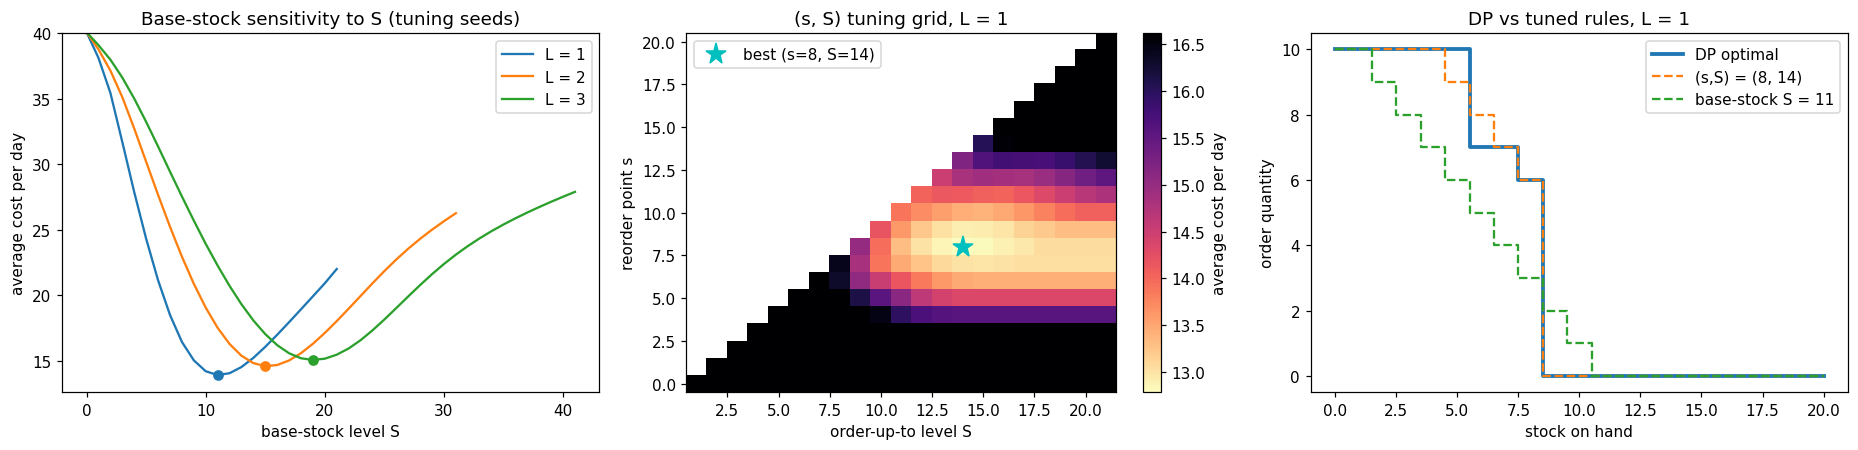

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
plotting.plot_cost_vs_S({L: t.table for L, t in bs_tuning.items()}, ax=axes[0])
axes[0].set_ylim(top=40)
plotting.plot_ss_heatmap(ss_tuning[1].table, ax=axes[1])
axes[1].set_title("(s, S) tuning grid, L = 1")
cfg1 = configs[1]
plotting.plot_policy_L1(vi_results[1].policy, cfg1, ax=axes[2], rules={
    f"(s,S) = ({ss_tuning[1].best['s']}, {ss_tuning[1].best['S']})":
        SSPolicy(ss_tuning[1].best["s"], ss_tuning[1].best["S"], cfg1),
    f"base-stock S = {bs_tuning[1].best['S']}": BaseStockPolicy(bs_tuning[1].best["S"], cfg1),
})
axes[2].set_title("DP vs tuned rules, L = 1")
fig.tight_layout()
plotting.save(fig, RESULTS / "rule_tuning.png")
plt.show()

**Sensitivity to S (protocol rule 6).** The base-stock cost curve is asymmetric:
- Setting S too low is expensive, because the shelf empties and every lost sale costs p = 10.
- Setting S too high costs only the holding cost h = 1 per unit, so the curve rises slowly.
- The best S grows with the delay, because the stock must cover demand over L + 1 days.

The (s, S) heatmap has a broad low-cost valley, so the rule is fairly robust to its parameters. On the right, the tuned (s, S) rule almost reproduces the DP policy at L = 1, while base-stock orders small amounts every day and keeps paying K.

## 5. Final evaluation

Each policy is evaluated greedily (no exploration, no tuning) on the **10 evaluation seeds**. Each seed is 20,000 days after a 1,000-day burn-in, and every method sees exactly the same demand sequence for a given seed. Gaps are computed per seed and then averaged (a paired comparison), so the confidence intervals reflect differences between methods rather than the luck of the demand draw.

Methods compared:
- **DP optimal:** greedy policy from value iteration (needs the full model).
- **(s,S) tuned** and **base-stock tuned:** the industry rules with grid-searched parameters.
- **base-stock naive:** S = mean demand over the L + 1 days an order must cover, i.e. what an untuned rule of thumb would do. It shows how much the tuning itself is worth.

The **best rule** at each L is whichever tuned rule had the lower *tuning* cost, so it is chosen without looking at the evaluation seeds.

In [10]:
def policies_for(L):
    cfg = configs[L]
    bs, ss = bs_tuning[L].best, ss_tuning[L].best
    naive_S = int(np.ceil(cfg.lam * (L + 1)))
    return {
        "DP optimal": (TabularPolicy(vi_results[L].policy, cfg), "-", vi_results[L].seconds + models[L].build_seconds),
        "(s,S) tuned": (SSPolicy(ss["s"], ss["S"], cfg), f"s={ss['s']}, S={ss['S']}", ss_tuning[L].seconds),
        "base-stock tuned": (BaseStockPolicy(bs["S"], cfg), f"S={bs['S']}", bs_tuning[L].seconds),
        "base-stock naive": (BaseStockPolicy(naive_S, cfg), f"S={naive_S}", 0.0),
    }


def evaluate_all(policies, cfg, best_rule):
    sims = {name: evaluate_policy(pol, cfg) for name, (pol, _, _) in policies.items()}
    rows = []
    for name, (pol, params, prep_seconds) in policies.items():
        r = sims[name]
        cost, cost_ci = mean_ci(r.avg_cost)
        gap_dp, gap_dp_ci = paired_gap_pct(r.avg_cost, sims["DP optimal"].avg_cost)
        gap_rule, gap_rule_ci = paired_gap_pct(r.avg_cost, sims[best_rule].avg_cost)
        rows.append(dict(method=name, params=params, cost=cost, cost_ci=cost_ci,
                         gap_dp_pct=gap_dp, gap_dp_ci=gap_dp_ci,
                         gap_best_rule_pct=gap_rule, gap_best_rule_ci=gap_rule_ci,
                         fill_rate=r.fill_rate.mean(), order_freq=r.order_freq.mean(),
                         holding=r.avg_holding.mean(), lost_penalty=r.avg_lost_penalty.mean(),
                         ordering=r.avg_ordering.mean(), overflow_per_day=r.overflow_rate.mean(),
                         prep_seconds=prep_seconds, eval_seconds=r.seconds))
    per_seed = pd.DataFrame({name: r.avg_cost for name, r in sims.items()}, index=pd.Index(EVAL_SEEDS, name="seed"))
    return pd.DataFrame(rows), per_seed


summaries, per_seed_costs = [], {}
for L, cfg in configs.items():
    best_rule = "(s,S) tuned" if ss_tuning[L].best["cost"] <= bs_tuning[L].best["cost"] else "base-stock tuned"
    table, per_seed = evaluate_all(policies_for(L), cfg, best_rule)
    table.insert(0, "L", L)
    table["best_rule"] = best_rule
    summaries.append(table)
    per_seed_costs[L] = per_seed

summary = pd.concat(summaries, ignore_index=True)
summary.to_csv(RESULTS / "final_evaluation.csv", index=False)
pd.concat(per_seed_costs, names=["L"]).to_csv(RESULTS / "per_seed_costs.csv")

display_cols = ["L", "method", "params", "cost", "cost_ci", "gap_dp_pct", "gap_dp_ci",
                "gap_best_rule_pct", "gap_best_rule_ci", "fill_rate", "order_freq", "overflow_per_day"]
summary[display_cols].set_index(["L", "method"])

params    cost  cost_ci  gap_dp_pct  gap_dp_ci  \
L method                                                                 
1 DP optimal                 -  12.765    0.034       0.000      0.000   
  (s,S) tuned        s=8, S=14  12.781    0.030       0.125      0.143   
  base-stock tuned        S=11  13.876    0.032       8.706      0.205   
  base-stock naive         S=8  16.386    0.053      28.369      0.284   
2 DP optimal                 -  13.349    0.041       0.000      0.000   
  (s,S) tuned       s=12, S=19  13.524    0.050       1.307      0.139   
  base-stock tuned        S=15  14.576    0.042       9.195      0.146   
  base-stock naive        S=12  16.193    0.056      21.304      0.177   
3 DP optimal                 -  13.700    0.045       0.000      0.000   
  (s,S) tuned       s=16, S=22  13.957    0.048       1.874      0.147   
  base-stock tuned        S=19  15.064    0.041       9.958      0.180   
  base-stock naive        S=16  16.124    0.062      17.694      0.146   

                    gap_best_rule_pct  gap_best_rule_ci  fill_rate  \
L method                                                             
1 DP optimal                   -0.124             0.143      0.950   
  (s,S) tuned                   0.000             0.000      0.948   
  base-stock tuned              8.570             0.148      0.955   
  base-stock naive             28.209             0.256      0.830   
2 DP optimal                   -1.290             0.136      0.937   
  (s,S) tuned                   0.000             0.000      0.947   
  base-stock tuned              7.786             0.164      0.944   
  base-stock naive             19.740             0.119      0.848   
3 DP optimal                   -1.839             0.142      0.928   
  (s,S) tuned                   0.000             0.000      0.935   
  base-stock tuned              7.936             0.183      0.939   
  base-stock naive             15.530             0.142      0.861   

                    order_freq  overflow_per_day  
L method                                          
1 DP optimal             0.490         0.000e+00  
  (s,S) tuned            0.483         0.000e+00  
  base-stock tuned       0.982         0.000e+00  
  base-stock naive       0.981         0.000e+00  
2 DP optimal             0.450         0.000e+00  
  (s,S) tuned            0.443         0.000e+00  
  base-stock tuned       0.982         0.000e+00  
  base-stock naive       0.980         0.000e+00  
3 DP optimal             0.452         9.000e-05  
  (s,S) tuned            0.482         4.500e-05  
  base-stock tuned       0.981         0.000e+00  
  base-stock naive       0.979         0.000e+00

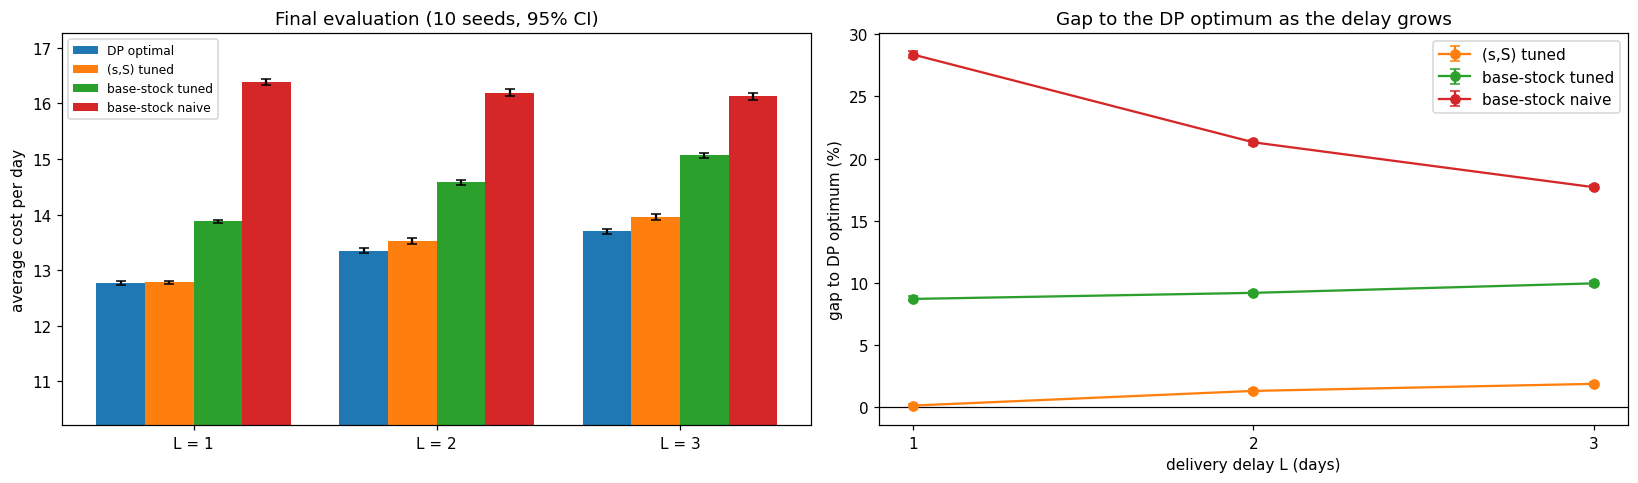

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
plotting.plot_methods_by_L(summary, ax=axes[0])
plotting.plot_sensitivity(summary, x="L", ax=axes[1])
axes[1].set_xticks(list(LEAD_TIMES))
axes[1].set_xlabel("delivery delay L (days)")
axes[1].set_title("Gap to the DP optimum as the delay grows")
fig.tight_layout()
plotting.save(fig, RESULTS / "final_evaluation.png")
plt.show()

In [12]:
breakdown = summary.set_index(["L", "method"])[["holding", "lost_penalty", "ordering", "cost"]]
breakdown.columns = ["holding", "lost-sales penalty", "ordering", "total"]
breakdown

holding  lost-sales penalty  ordering   total
L method                                                         
1 DP optimal          4.527               1.986     6.252  12.765
  (s,S) tuned         4.501               2.071     6.210  12.781
  base-stock tuned    3.357               1.788     8.732  13.876
  base-stock naive    1.359               6.802     8.225  16.386
2 DP optimal          4.837               2.514     5.997  13.349
  (s,S) tuned         5.395               2.128     6.001  13.524
  base-stock tuned    3.666               2.224     8.686  14.576
  base-stock naive    1.822               6.078     8.293  16.193
3 DP optimal          4.859               2.868     5.973  13.700
  (s,S) tuned         5.201               2.606     6.150  13.957
  base-stock tuned    3.970               2.430     8.665  15.064
  base-stock naive    2.222               5.560     8.341  16.124

## 6. Sensitivity to the lost-sales penalty p

How much the policies leave on the table depends on the cost structure. Here the penalty per lost sale is varied (p = 5, 10, 20) for L = 1 and L = 2. For each p, everything is re-solved and re-tuned from scratch, then evaluated with the same protocol.

In [13]:
sens_rows = []
t0 = time.perf_counter()
for L in (1, 2):
    for p in (5.0, 10.0, 20.0):
        cfg = DEFAULT.with_(L=L, p=p)
        vi = value_iteration(build_model(cfg))
        bs, ss = tune_base_stock(cfg), tune_ss(cfg)
        best_rule = "(s,S) tuned" if ss.best["cost"] <= bs.best["cost"] else "base-stock tuned"
        pols = {
            "DP optimal": (TabularPolicy(vi.policy, cfg), "-", vi.seconds),
            "(s,S) tuned": (SSPolicy(ss.best["s"], ss.best["S"], cfg), f"s={ss.best['s']}, S={ss.best['S']}", ss.seconds),
            "base-stock tuned": (BaseStockPolicy(bs.best["S"], cfg), f"S={bs.best['S']}", bs.seconds),
        }
        table, _ = evaluate_all(pols, cfg, best_rule)
        table.insert(0, "p", p)
        table.insert(0, "L", L)
        sens_rows.append(table)
sensitivity = pd.concat(sens_rows, ignore_index=True)
sensitivity.to_csv(RESULTS / "sensitivity_p.csv", index=False)
print(f"sensitivity study: {time.perf_counter() - t0:.1f} s")
sensitivity[["L", "p", "method", "params", "cost", "cost_ci", "gap_dp_pct", "gap_dp_ci", "fill_rate"]].set_index(["L", "p", "method"])

sensitivity study: 71.6 s


params    cost  cost_ci  gap_dp_pct  gap_dp_ci  \
L p    method                                                                 
1 5.0  DP optimal                 -  11.303    0.020       0.000      0.000   
       (s,S) tuned        s=6, S=13  11.344    0.027       0.363      0.170   
       base-stock tuned        S=10  12.681    0.021      12.193      0.128   
  10.0 DP optimal                 -  12.765    0.034       0.000      0.000   
       (s,S) tuned        s=8, S=14  12.781    0.030       0.125      0.143   
       base-stock tuned        S=11  13.876    0.032       8.706      0.205   
  20.0 DP optimal                 -  14.016    0.034       0.000      0.000   
       (s,S) tuned       s=10, S=15  14.040    0.036       0.172      0.087   
       base-stock tuned        S=13  15.065    0.039       7.487      0.208   
2 5.0  DP optimal                 -  11.575    0.024       0.000      0.000   
       (s,S) tuned       s=10, S=16  11.894    0.023       2.756      0.128   
       base-stock tuned        S=13  13.056    0.027      12.790      0.134   
  10.0 DP optimal                 -  13.349    0.041       0.000      0.000   
       (s,S) tuned       s=12, S=19  13.524    0.050       1.307      0.139   
       base-stock tuned        S=15  14.576    0.042       9.195      0.146   
  20.0 DP optimal                 -  14.892    0.045       0.000      0.000   
       (s,S) tuned       s=14, S=21  14.981    0.056       0.602      0.242   
       base-stock tuned        S=17  15.949    0.049       7.103      0.161   

                         fill_rate  
L p    method                       
1 5.0  DP optimal            0.878  
       (s,S) tuned           0.887  
       base-stock tuned      0.926  
  10.0 DP optimal            0.950  
       (s,S) tuned           0.948  
       base-stock tuned      0.955  
  20.0 DP optimal            0.983  
       (s,S) tuned           0.984  
       base-stock tuned      0.986  
2 5.0  DP optimal            0.870  
       (s,S) tuned           0.886  
       base-stock tuned      0.887  
  10.0 DP optimal            0.937  
       (s,S) tuned           0.947  
       base-stock tuned      0.944  
  20.0 DP optimal            0.973  
       (s,S) tuned           0.977  
       base-stock tuned      0.977

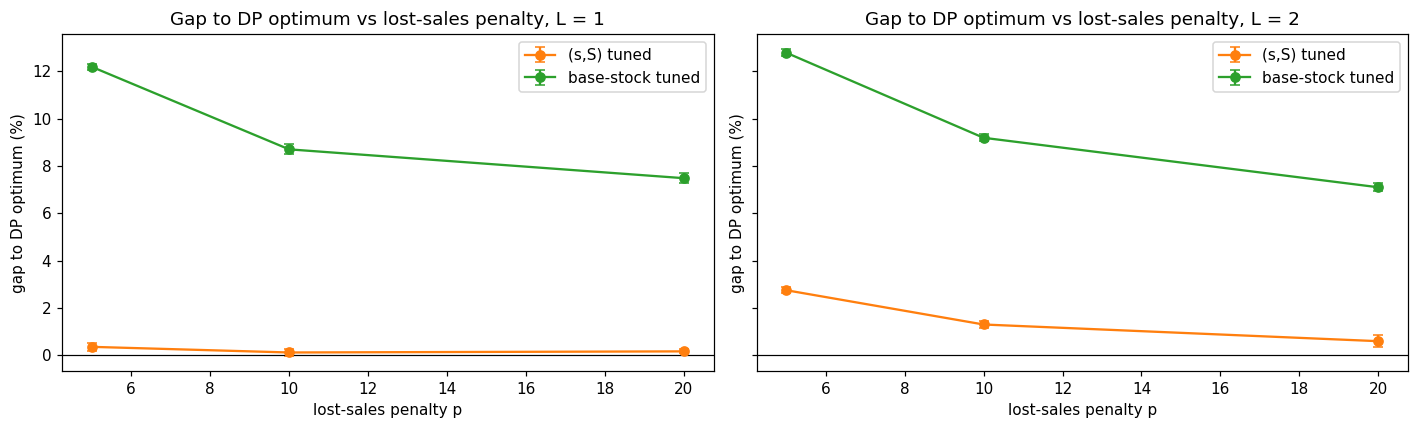

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, L in zip(axes, (1, 2)):
    plotting.plot_sensitivity(sensitivity[sensitivity.L == L], x="p", ax=ax)
    ax.set_title(f"Gap to DP optimum vs lost-sales penalty, L = {L}")
    ax.set_xlabel("lost-sales penalty p")
fig.tight_layout()
plotting.save(fig, RESULTS / "sensitivity_p.png")
plt.show()

**Reading the sensitivity results.**
- **Base-stock** suffers most when lost sales are cheap (p = 5). Shortages then matter less than the fixed cost of ordering every day, and that cost is exactly what base-stock ignores.
- **(s, S) at L = 1** stays within about 0.4% of optimal for every p.
- **(s, S) at L = 2** loses more when p is small (about 2.8% at p = 5, 0.6% at p = 20). When stockouts are cheap, the optimal policy deliberately runs the shelf low and times orders using the pipeline in detail, which a single position threshold cannot express.

So how much there is to gain over the industry rules depends on both the delay and the cost structure. Parts 2 and 3 will test whether learned policies capture that gain.

## 7. Compute cost (protocol rule 5)

Wall-clock seconds on the hardware listed in the setup cell:
- **preparation:** building the model and running value iteration for DP, or the full grid search for the rules
- **evaluation:** simulating 10 seeds x 21,000 days, vectorized over seeds

In [15]:
timing = summary.pivot(index="method", columns="L", values="prep_seconds").round(2)
timing.columns = [f"prep L={L} (s)" for L in timing.columns]
eval_time = summary.pivot(index="method", columns="L", values="eval_seconds").round(2)
eval_time.columns = [f"eval L={L} (s)" for L in eval_time.columns]
compute = pd.concat([timing, eval_time], axis=1)
compute.to_csv(RESULTS / "compute_time.csv")
print(hardware["cpu"], "|", hardware["logical cores"], "logical cores |", hardware["os"])
compute

Intel(R) Xeon(R) CPU @ 2.20GHz | 2 logical cores | Linux-6.6.159+-x86_64-with-glibc2.39


,prep L=1 (s),prep L=2 (s),prep L=3 (s),eval L=1 (s),eval L=2 (s),eval L=3 (s)
method,,,,,,
"(s,S) tuned",3.92,5.67,6.39,1.18,1.30,2.92
DP optimal,0.07,0.42,6.87,1.12,1.01,1.20
base-stock naive,0.00,0.00,0.00,1.16,1.32,1.34
base-stock tuned,3.98,3.25,3.36,1.18,1.37,1.33


## 8. Summary for Presentation 1

In [16]:
key = summary[summary.method != "DP optimal"].set_index(["L", "method"])[["cost", "gap_dp_pct", "gap_dp_ci"]]
for L in LEAD_TIMES:
    dp_cost = summary.query("L == @L and method == 'DP optimal'").cost.item()
    ss = key.loc[(L, "(s,S) tuned")]
    bs = key.loc[(L, "base-stock tuned")]
    nv = key.loc[(L, "base-stock naive")]
    print(f"L={L}: DP {dp_cost:.2f}/day | (s,S) +{ss.gap_dp_pct:.2f}% (+/-{ss.gap_dp_ci:.2f}) | "
          f"base-stock +{bs.gap_dp_pct:.1f}% | naive base-stock +{nv.gap_dp_pct:.1f}%")

L=1: DP 12.77/day | (s,S) +0.12% (+/-0.14) | base-stock +8.7% | naive base-stock +28.4%
L=2: DP 13.35/day | (s,S) +1.31% (+/-0.14) | base-stock +9.2% | naive base-stock +21.3%
L=3: DP 13.70/day | (s,S) +1.87% (+/-0.15) | base-stock +10.0% | naive base-stock +17.7%


**Findings so far** (numbers are in the table above and in `results/part1/`):

1. **The MDP is solved exactly for L = 1 to 3** in at most a couple of seconds. This gives a ground-truth optimum against which every later method is measured.
2. **The tuned (s, S) rule is almost optimal at L = 1.** Its gap is within the confidence interval of zero, and the DP policy itself has an (s, S) shape. With a short delay there is little for RL to gain.
3. **The (s, S) gap grows with the delay**, from about 0.1% at L = 1 to about 2% at L = 3. Under lost sales the inventory position stops being a sufficient summary once more orders are in transit, so the optimal policy depends on *which* orders arrive *when*. This is where a learned policy could pay off.
4. **Base-stock is about 9 to 10% worse than optimal** with a fixed order cost K = 5, because it orders every day. Tuning still matters: the naive rule of thumb is 18 to 28% worse than optimal.
5. **Cost structure matters too.** At L = 2 the (s, S) gap ranges from 0.6% (p = 20) to 2.8% (p = 5).
6. **Exact DP stops scaling at L = 5 to 6** (model memory 0.85 GB to 9 GB). That leaves room for approximate methods.

**Next (Part 2):** tabular Q-learning on the same environment for L = 1 to 3. It will be evaluated with learning curves over 10 seeds, sample efficiency (environment steps to come within 5% of the DP optimum) and sensitivity to alpha and epsilon. The question is how close model-free learning gets to the optimum computed here.